# Stroke Prediction Dataset: Exploratory Data Analysis

**Goal:** understand the Kaggle Stroke Prediction Dataset (fedesoriano) before any modelling: what each column holds, how clean the data is, and which features seem to be linked with stroke.

**Plan:**
1. Load the data and look at its structure (shape, types, summary statistics)
2. Clean it (missing values, duplicates)
3. Explore it with statistics and visualizations (histogram, countplot, boxplot, pairplot)
4. Summarize what I found



## 1) Importing Libraries

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


These are the four libraries used throughout: **NumPy** for numerical work (percentiles), **Pandas** for loading and handling the table, and **Matplotlib** and **Seaborn** for plotting. Seaborn is built on Matplotlib and gives nicer default statistical plots.

## 2) Loading the Dataset

In [ ]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

`pd.read_csv` loads the file into a DataFrame called `df`. I use `head()` for a quick check that it loaded correctly, instead of printing all 5,110 rows, which would be unreadable.

## 3) Viewing the Rows of the Dataset
Top 10, last 10 and a random sample of 10 rows.

In [6]:
df.head(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


In [7]:
df.tail(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5100,68398,Male,82.0,1,0,Yes,Self-employed,Rural,71.97,28.3,never smoked,0
5101,36901,Female,45.0,0,0,Yes,Private,Urban,97.95,24.5,Unknown,0
5102,45010,Female,57.0,0,0,Yes,Private,Rural,77.93,21.7,never smoked,0
5103,22127,Female,18.0,0,0,No,Private,Urban,82.85,46.9,Unknown,0
5104,14180,Female,13.0,0,0,No,children,Rural,103.08,18.6,Unknown,0
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [8]:
df.sample(n=10, random_state=42)  # 10 random rows; random_state makes it repeatable

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
4688,40041,Male,31.00,0,0,No,Self-employed,Rural,64.85,23.0,Unknown,0
4478,55244,Male,40.00,0,0,Yes,Self-employed,Rural,65.29,28.3,never smoked,0
3849,70992,Female,8.00,0,0,No,children,Urban,74.42,22.5,Unknown,0
4355,38207,Female,79.00,1,0,Yes,Self-employed,Rural,76.64,19.5,never smoked,0
3826,8541,Female,75.00,0,0,Yes,Govt_job,Rural,94.77,27.2,never smoked,0
3951,2467,Female,79.00,1,0,Yes,Self-employed,Rural,92.43,NaN,never smoked,0
3396,19828,Female,56.00,1,0,Yes,Private,Rural,97.37,34.1,smokes,0
465,621,Male,69.00,0,0,Yes,Private,Rural,101.52,26.8,smokes,0
410,54975,Male,7.00,0,0,No,Self-employed,Rural,64.06,18.9,Unknown,0
1632,57485,Female,1.48,0,0,No,children,Rural,55.51,18.5,Unknown,0


`head()` and `tail()` show the start and end of the file, and `sample()` gives a random slice so I am not only looking at one end of the data. Things I notice: `bmi` already shows `NaN` (missing) in a few rows, there are ages like 1.48 (infants), and `work_type` has a `children` category.

## 4) Shape of the Dataset
Number of rows and columns.

In [9]:
df.shape

(5110, 12)

In [10]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

rows 5110
columns 12


The dataset has **5,110 rows (patients) and 12 columns**. That is a reasonable size for EDA: enough rows for patterns to show up, small enough to run quickly.

## 5) Dataset Information
Column names, data types, non-null counts and memory usage.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


`info()` shows each column's data type and non-null count. Every column has 5,110 values **except `bmi`, which has 4,909**, so 201 values are missing. Five columns are text (categorical) and the rest are numeric. `hypertension`, `heart_disease` and `stroke` are stored as numbers but are really yes/no categories.

## 6) Summary Statistics

In [12]:
df.describe(include= 'all')

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


`describe(include='all')` gives statistics for both numeric and categorical columns. Findings: average age is about **43 years** (range 0.08 to 82); average glucose is about **106** with a standard deviation of 45, so it varies a lot; only about 9.7% of patients have hypertension and about 5.4% have heart disease. `gender` has 3 unique values, so one category is unusual (not `Male`/`Female`).

## 7) Missing Values

In [13]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [ ]:
# heatmap of missing values
plt.figure(figsize=(15, 7))
sns.heatmap(df.isnull(), cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

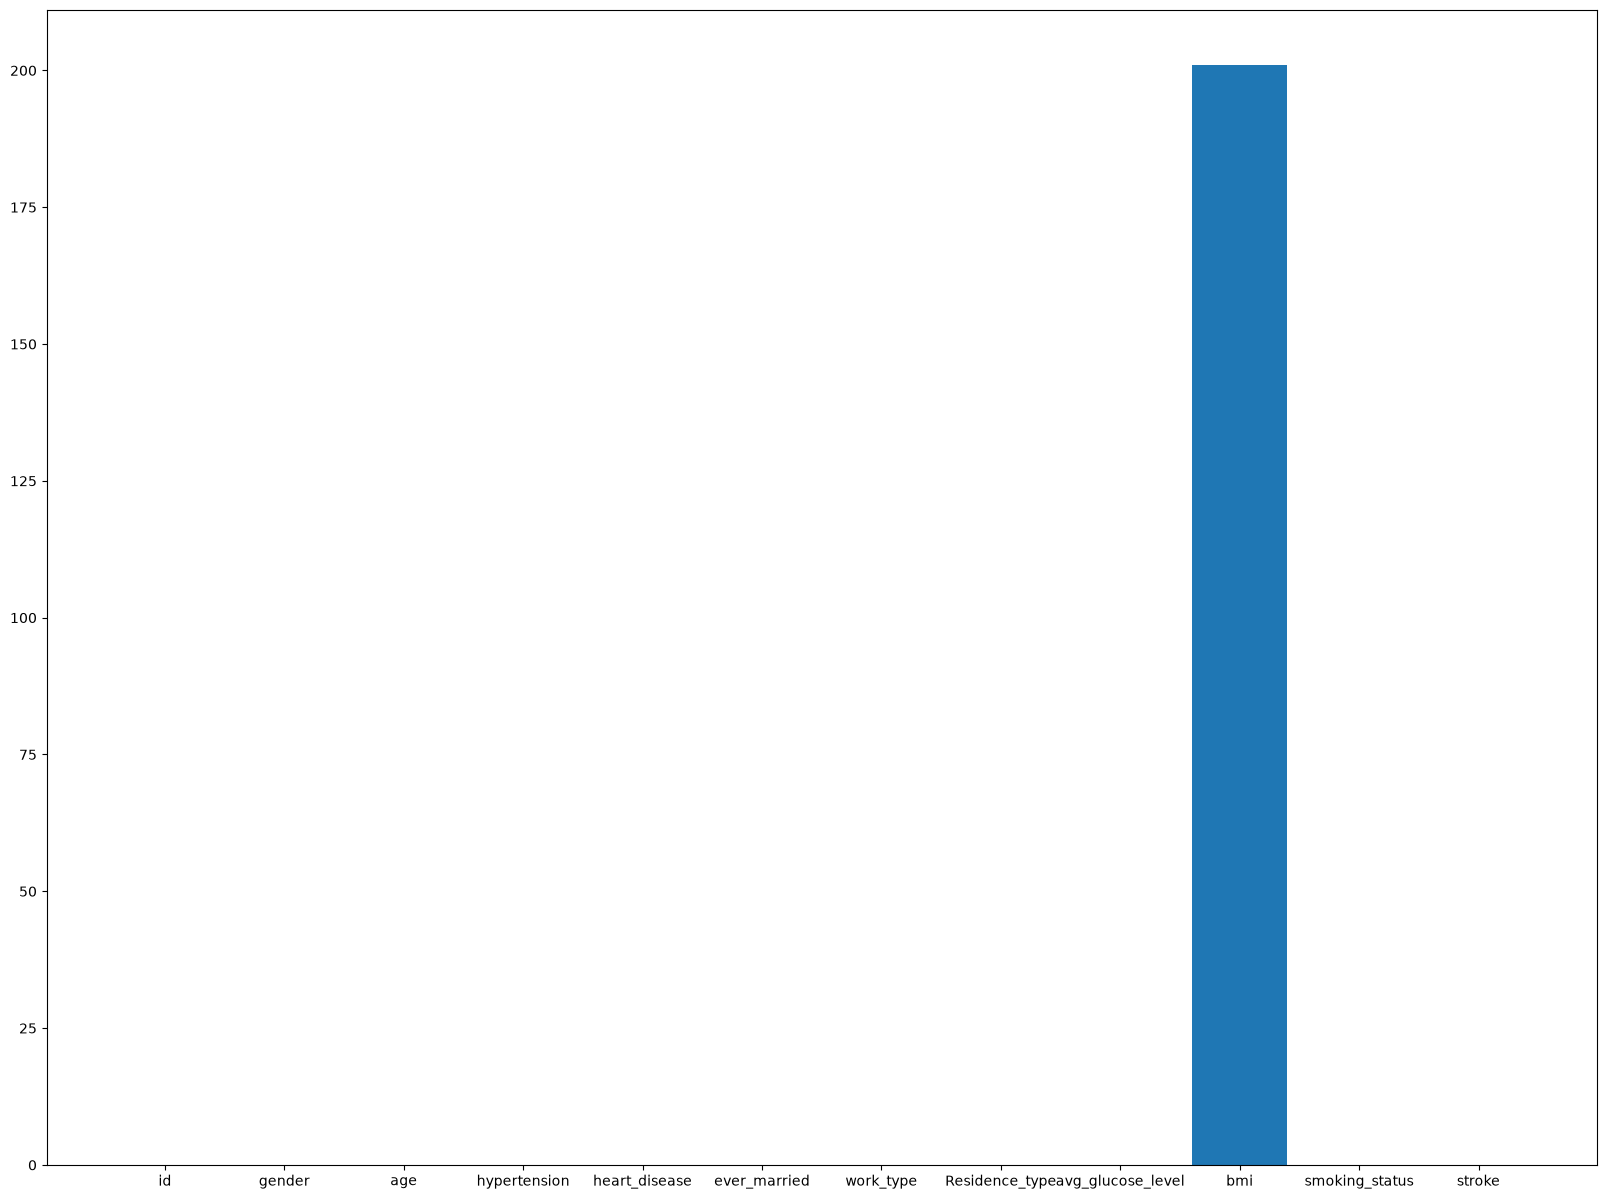

In [15]:
# bar plot of missing values per column
plt.figure(figsize=(10, 5))
plt.bar(df.columns, df.isnull().sum())
plt.xticks(rotation=45)
plt.ylabel("Missing values")
plt.title("Missing Values per Column")
plt.show()

Only **`bmi` has missing values (201)**, which the heatmap (a thin line of missing cells in one column) and the bar chart both confirm. All other columns are complete.

In [16]:
# Only bmi has missing values (201). I will fill them with the median,
# because the median is less affected by outliers than the mean.

In [17]:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

I fill the missing `bmi` values with the **median** rather than dropping rows. Dropping would throw away 201 patients, and since the stroke cases are already rare, I do not want to lose any. The median is used instead of the mean because BMI has high outliers (visible later in the boxplot), which would pull the mean up. After filling, `isnull().sum()` shows 0 missing values everywhere.

*Limitation: filling with one value for everyone reduces the natural variation in BMI. It is a simple choice, not a perfect one.*

## 8) Duplicate Records

In [18]:
df.duplicated().sum()

np.int64(0)

`duplicated().sum()` is 0, so there are no repeated rows (each `id` is also unique, as the next section shows). No data is lost in this step.

In [19]:
# No duplicate rows, so nothing needs to be dropped.

In [20]:
df = df.drop_duplicates()

This line is kept as a safety step: if duplicates were present it would remove them, and here it changes nothing.

## 9) Unique Values per Column

In [21]:
df.nunique()

id                   5110
gender                  3
age                   104
hypertension            2
heart_disease           2
ever_married            2
work_type               5
Residence_type          2
avg_glucose_level    3979
bmi                   418
smoking_status          4
stroke                  2
dtype: int64

`nunique()` tells me which columns are categorical and which are continuous. `id` has 5,110 unique values, so it is just an identifier and carries no information about stroke. `gender` has 3 values, `work_type` 5 and `smoking_status` 4. `age`, `bmi` and `avg_glucose_level` have many distinct values, so they are continuous.

## 10) Average Age, BMI and Glucose for Stroke vs Non-Stroke Patients

In [22]:
df.groupby("stroke")[["age", "bmi", "avg_glucose_level"]].mean()

,age,bmi,avg_glucose_level
stroke,,,
0,41.971545,28.799115,104.795513
1,67.728193,30.090361,132.544739


Grouping by `stroke` and averaging compares the two groups directly. Patients who had a stroke are on average much **older (about 67.7 vs 42.0 years)** and have a **higher average glucose (about 132.5 vs 104.8)**. BMI differs only slightly (about 30.1 vs 28.8). So age and glucose look like the most promising features here.

## 11) Age Percentiles

In [23]:
age = df["age"].to_numpy()

percentiles = np.percentile(age, [25, 50, 75, 95])

print("25th percentile:", percentiles[0])
print("50th percentile:", percentiles[1])
print("75th percentile:", percentiles[2])
print("95th percentile:", percentiles[3])

25th percentile: 25.0
50th percentile: 45.0
75th percentile: 61.0
95th percentile: 79.0


Percentiles show how the ages are spread: 25% of patients are 25 or younger, the median is 45, 75% are 61 or younger and 95% are 79 or younger. The median (45) is close to the mean (43.2), so the age distribution is fairly balanced and not heavily skewed.

## 12) Age Histogram with Dashed Mean Line

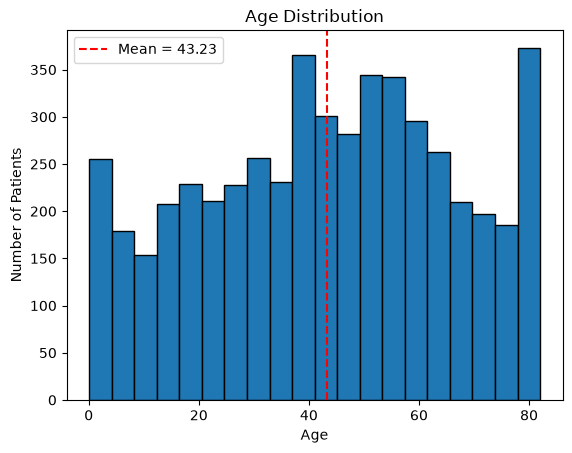

In [24]:
mean_age = df["age"].mean()

plt.hist(df["age"], bins=20, edgecolor="black")

plt.axvline(
    mean_age,
    color="red",
    linestyle="--",
    label=f"Mean = {mean_age:.2f}"
)

plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.title("Age Distribution")
plt.legend()

plt.show()

The histogram shows the age distribution; the dashed red line is the mean (43.23). Ages are spread out quite evenly, with no single dominant peak, but there are noticeable bars around 40 and at the oldest ages (about 80). The dataset therefore covers all age groups, from babies to elderly patients, which matters because stroke risk depends strongly on age.

## 13) Stroke Cases by Smoking Status

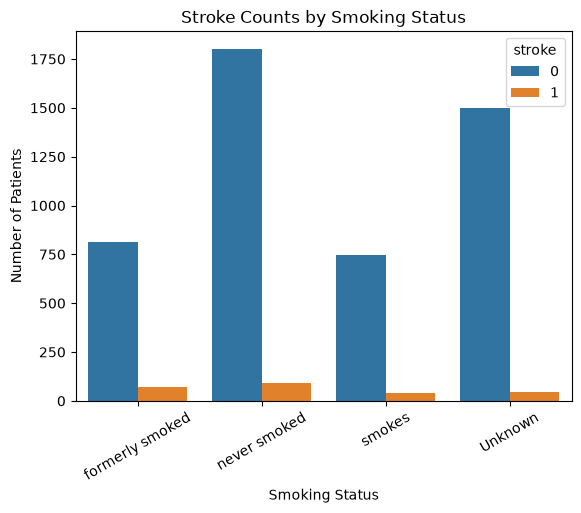

In [25]:
sns.countplot(
    data=df,
    x="smoking_status",
    hue="stroke"
)

plt.title("Stroke Counts by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)

plt.show()

The countplot compares stroke (orange) and no stroke (blue) within each smoking category. The most important thing is that **stroke cases are very rare compared to non-stroke in every group**. This is a class imbalance and would need care in any prediction model. Because the orange bars are so small, raw counts are hard to compare between groups. Also, `Unknown` smoking status is a large group, so smoking status here is incomplete information. Raw counts alone do not prove that smoking causes or prevents stroke; the groups have different sizes (and different ages), so I would need proportions to compare them fairly.

## 14) BMI by Work Type

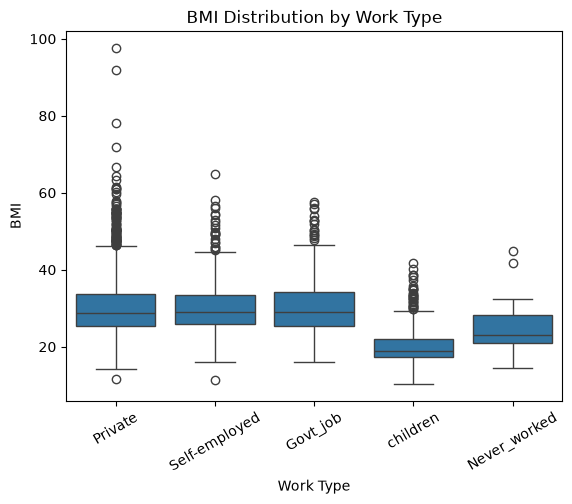

In [26]:
sns.boxplot(
    data=df,
    x="work_type",
    y="bmi"
)

plt.title("BMI Distribution by Work Type")
plt.xlabel("Work Type")
plt.ylabel("BMI")
plt.xticks(rotation=30)

plt.show()

The boxplot shows the BMI spread for each work type. The median BMI is similar for `Private`, `Self-employed` and `Govt_job` (roughly high 20s). The **`children` group has clearly lower BMI**, which makes sense because they are young. `Private` has many high outliers, with a few BMIs near 100, which are probably data errors or extreme cases. These outliers are the reason I used the median to fill the missing BMI values.

## 15) Pairplot of Age, BMI and Glucose by Stroke Status

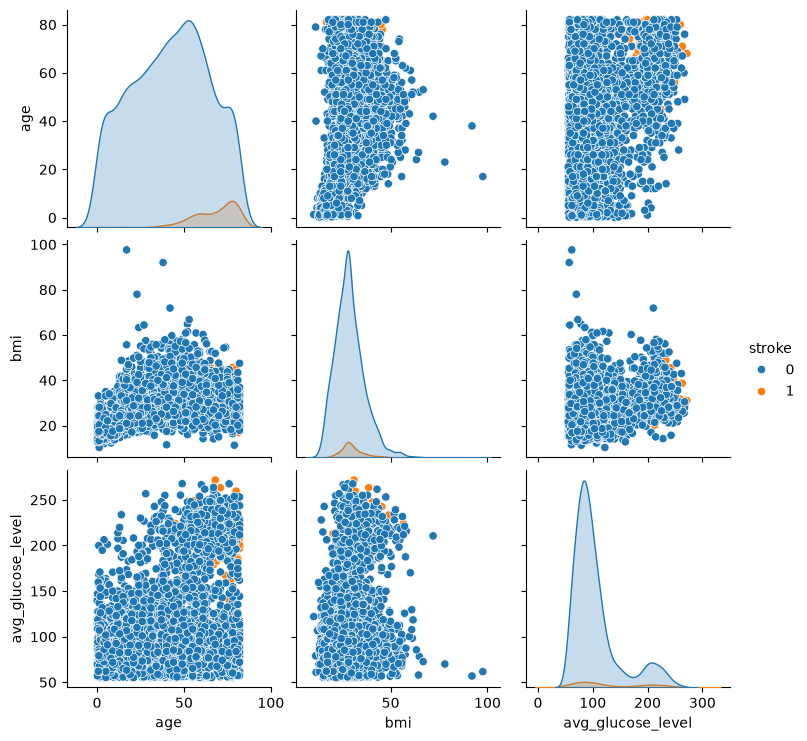

In [27]:
sns.pairplot(
    df,
    vars=["age", "bmi", "avg_glucose_level"],
    hue="stroke"
)

plt.show()

The pairplot shows every pair of the three numeric features, coloured by stroke (orange = stroke). The diagonal shows each feature's distribution. What stands out: **stroke cases (orange) cluster at higher ages**, mostly above about 50, and many sit at **higher glucose levels**. Glucose has two humps (a large group around 80 to 100 and a smaller one near 200). BMI shows no clear separation between stroke and non-stroke. This agrees with the group averages computed earlier.